In [89]:
# brief
# get_mel_spectrogram	Converts audio waveform to Mel spectrogram
# prepare_text	Converts text input to phonemes
# diffusion_schedule	Defines noise schedule for diffusion process
# forward_process	Adds noise to audio data
# denoise_step	Removes noise using a neural network
# Generator	U-Net like structure for generating speech
# Discriminator	Evaluates generated speech quality
# adversarial_loss	Loss function for GAN training
# diffusion_loss	Loss function for noise prediction
# train_step	Performs one training step for both Generator and Discriminator

#LibSpeech dataset

# Text Processing: Handles the conversion of input text into suitable features for the model.​
# arXiv
# +1
# ResearchGate
# +1

# Acoustic Model: Implements the model that maps text features to mel-spectrograms.​

# Diffusion Decoder: Contains the diffusion model enhanced with GAN training for high-fidelity spectrogram generation.​

# Vocoder: Utilizes models like HiFi-GAN to synthesize waveforms from mel-spectrograms.

# Fix: You must train for many epochs (e.g. thousands of steps) before realistic speech appears. Otherwise, the generator just outputs random Mel values, and Griffin-Lim turns that into “static.”

Tutorials
https://github.com/keonlee9420/DiffGAN-TTS
https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html

In [90]:
# Core Parts of a DiffGAN-TTS-style TTS system:
# Text Encoder – Turns input text into embeddings.

# Acoustic Predictor (e.g. mel-spectrogram generator) – Uses a diffusion model + GAN to predict a mel-spectrogram.

# Vocoder – Converts mel-spectrogram to waveform (e.g., use pre-trained HiFi-GAN or similar).

# For real speech, expect 50–100+ mel frames for a 1–2 second utterance.

# Positional encodings

# Attention-based duration predictor or aligner

# HiFi-GAN or other neural vocoder



In [91]:
# Steps to train with dataset
# Load LibriSpeech Dataset (via torchaudio)

# Text Preprocessing (convert transcript to token IDs)

# Audio Preprocessing (convert waveform to mel-spectrogram)

# Batch and Feed to Model

# Train using your train loop

In [92]:
# Load one .wav file

# Get its transcript

# Convert it to token sequence and mel-spectrogram

# Pass it through your DiffGAN_TTS model

# See if it outputs something reasonable

# Predict duration explicitly (later)
# Once your architecture is upgraded to match true DiffGAN-TTS, you’ll want to:

# Add a length regulator / duration model

# Expand text → target length mel spectrogram

In [125]:
import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
import string
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
import torch.nn.utils.rnn as rnn_utils
import pandas as pd
import os
import matplotlib.pyplot as plt
import math
import numpy as np
from torch.nn.utils.rnn import pad_sequence

In [94]:
#PreProcessing Funcs
CHAR_VOCAB = {c: i+1 for i, c in enumerate(string.ascii_lowercase + " '")}
CHAR_VOCAB["<pad>"] = 0

def text_to_sequence(text):
    return [CHAR_VOCAB.get(c, 0) for c in text.lower() if c in CHAR_VOCAB]

In [126]:
# mel_transform = T.MelSpectrogram(
#     sample_rate=16000,
#     n_fft=1024,
#     hop_length=256,
#     n_mels=80
# )

mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=256,
    n_mels=80,
    f_min=0.0,
    f_max=8000.0,
    mel_scale='htk',       # ✅ match
    norm='slaney'          # ✅ match
)

def waveform_to_mel(waveform):
    mel = mel_transform(waveform)
    mel_db = torchaudio.transforms.AmplitudeToDB()(mel)
    return mel_db.squeeze(0).transpose(0, 1)  # (Time, Mel)

In [96]:
# --- Load one file ---
# metadata_path = 'LJSpeech-1.1\LJSpeech-1.1\metadata.csv'
metadata_path = r"LJSpeech-1.1\LJSpeech-1.1\metadata.csv"

df = pd.read_csv(metadata_path, sep='|', header=None, names=["file_id", "text", "normalized_text"])

# Example sample
file_id = df.iloc[0]["file_id"]
text = df.iloc[0]["normalized_text"]
wav_path = os.path.join("LJSpeech-1.1/LJSpeech-1.1/wavs", f"{file_id}.wav")

# --- Preprocess ---
waveform, sample_rate = torchaudio.load(wav_path)
text_seq = torch.tensor([text_to_sequence(text)])  # (1, seq_len)
mel = waveform_to_mel(waveform)                    # (time, mel)

print("Text:", text)
print("Input tokens:", text_seq.shape)
print("Mel target shape:", mel.shape)


Text: Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition
Input tokens: torch.Size([1, 149])
Mel target shape: torch.Size([832, 80])


In [97]:
def collate_fn(batch):
    texts, mels, durations = zip(*batch)

    text_lens = torch.tensor([len(t) for t in texts])
    text_padded = pad_sequence(texts, batch_first=True)     # Already tensors
    mel_padded = pad_sequence(mels, batch_first=True)
    duration_padded = pad_sequence(durations, batch_first=True)

    return text_padded, mel_padded, duration_padded, text_lens

In [98]:
def get_noise_schedule(num_steps=1000, schedule_type="cosine"):
    if schedule_type == "linear":
        return torch.linspace(1e-4, 0.02, num_steps)  # linear beta schedule
    elif schedule_type == "cosine":
        steps = torch.arange(num_steps + 1, dtype=torch.float32) / num_steps
        alphas_cumprod = torch.cos((steps + 0.008) / 1.008 * math.pi / 2) ** 2
        alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
        betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
        return torch.clip(betas, 1e-6, 0.999)


Added in a learned duration predictor, regulator that expands text features to mel length, model shoul now be able to generate outputs with T ≈ 800 mel frames

Add an aligner that says how many mel frames each token occupies

now have .TextGrid files for all  utterances in the aligned_output/ folder via running MFA on English dictionary and pretrained acoustic model, each textgrid contains timestamps (xmin, xmax) for each word or silence

read each .TextGrid file.

Extract the word/syllable/phoneme durations (depending on your need).

Save them as LJ001-0001_durations.npy, LJ001-0002_durations.npy

Your SimpleLJSDataset:

Loads text and .wav audio.

Converts audio to mel spectrogram.

Loads true_durations from durations/{file_id}_durations.npy.

Your training loop:

Predicts durations.

Computes L1Loss between predicted and true durations.

Uses duration prediction with LengthRegulator to expand embeddings.

Trains the diffusion blocks and GAN based on mel targets.

Combines duration_loss and g_loss for generator updates.



In [99]:
# -----------------------
# TEXT ENCODER
# -----------------------
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)

    def forward(self, x):
        x = self.embedding(x)  # (B, T_text, E)
        out, _ = self.lstm(x)
        return out  # (B, T_text, H)
    
# -----------------------
# DIFFUSION BLOCK (Simplified)
# -----------------------
class DiffusionBlock(nn.Module):
    def __init__(self, mel_dim, hidden_dim, diffusion_steps=1000, schedule_type="cosine"):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(mel_dim, hidden_dim),
            nn.ReLU(),
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, mel_dim)
        )
        self.betas = get_noise_schedule(diffusion_steps, schedule_type)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)  # used for scaling

    def forward(self, x, t, add_noise=True):
        if add_noise:
            # get alpha_bar[t], shape-match with x
            alpha_bar = self.alpha_bars[t].to(x.device)  # scalar
            noise = torch.randn_like(x)
            x = torch.sqrt(alpha_bar) * x + torch.sqrt(1 - alpha_bar) * noise
        return self.mlp(x)

    

# -----------------------
# GENERATOR (Mel Generator)
# -----------------------
class MelGenerator(nn.Module):
    def __init__(self, hidden_dim, mel_dim, diffusion_steps=10):
        super().__init__()
        self.diffusion_blocks = nn.ModuleList(
            [DiffusionBlock(mel_dim, hidden_dim) for _ in range(diffusion_steps)]
        )
        self.output_activation = nn.Tanh()  # Mel spectrograms are typically in [-1, 1]

    def forward(self, x):
        for step, block in enumerate(self.diffusion_blocks):
            x = block(x, step)
        return self.output_activation(x)  # restrict values between -1 and 1
    
# -----------------------
# DISCRIMINATOR (Simplified)
# -----------------------
class Discriminator(nn.Module):
    def __init__(self, mel_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(mel_dim, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # x shape: (B, T, mel_dim)
        B, T, D = x.shape
        x = x.reshape(B * T, D)
        out = self.net(x)  # (B * T, 1)
        out = out.view(B, T)  # flatten time dimension
        return out.mean(dim=1)  # return (B,)

    
# -----------------------
# DIFFGAN-TTS WRAPPER
# -----------------------
class DiffGAN_TTS(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, mel_dim, diffusion_steps=10):
        super().__init__()
        self.text_encoder = TextEncoder(vocab_size, embed_dim, hidden_dim)
        self.duration_predictor = DurationPredictor(hidden_dim)
        self.length_regulator = LengthRegulator()
        self.text_to_mel_proj = nn.Linear(hidden_dim, mel_dim)
        self.mel_generator = MelGenerator(hidden_dim, mel_dim, diffusion_steps)
        self.discriminator = Discriminator(mel_dim)

    def forward(self, text_seq):
        # Step 1: Encode text
        text_features = self.text_encoder(text_seq)  # (B, T_text, hidden_dim)

        # Step 2: Predict durations and expand with regulator
        durations = self.duration_predictor(text_features)  # (B, T_text)
        regulated = self.length_regulator(text_features, durations)  # (B, T_mel, hidden_dim)

        # Step 3: Project to mel dimension
        projected = self.text_to_mel_proj(regulated)  # (B, T_mel, mel_dim)

        # Step 4: Apply diffusion blocks
        x = projected
        for step, block in enumerate(self.mel_generator.diffusion_blocks):
            x = block(x, step, add_noise=self.training)  # ✅ noise only during training

        return x  # (B, T_mel, mel_dim)

 
class DurationRegulator(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, text_embeddings, durations):
        """
        text_embeddings: (B, T_text, H)
        durations: (B, T_text) — number of frames to repeat per token
        Returns: (B, T_mel, H)
        """
        out = []
        for i in range(text_embeddings.size(0)):  # loop over batch
            expanded = [text_embeddings[i, j].repeat(durations[i, j], 1)
                        for j in range(text_embeddings.size(1))]
            out.append(torch.cat(expanded, dim=0))  # (T_mel_i, H)
        
        # Pad to max length in batch
        max_len = max([t.size(0) for t in out])
        out_padded = [F.pad(t, (0, 0, 0, max_len - t.size(0))) for t in out]
        return torch.stack(out_padded)  # (B, T_mel_max, H)
    
    
class DurationPredictor(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        out = self.net(x).squeeze(-1)  # (B, T)
        out = torch.clamp(out, min=1.0)  # ensure duration is at least 1
        
        durations = out.round().long()  # convert to int

        # ✅ Add this debug info:
        # print("Duration stats:")
        # print("  Min:", durations.min().item())
        # print("  Max:", durations.max().item())
        # print("  Mean:", durations.float().mean().item())
        return durations       # convert to int
    
    
    
class LengthRegulator(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, encoder_output, durations):
        # encoder_output: (B, T_text, hidden_dim)
        # durations: (B, T_text) - number of repetitions per token

        output = []
        for i in range(encoder_output.size(0)):  # iterate over batch
            expanded = [
                encoder_output[i, j].repeat(int(durations[i, j].item()), 1)
                for j in range(encoder_output.size(1))
            ]
            expanded = torch.cat(expanded, dim=0)  # shape: (T_mel, hidden_dim)
            output.append(expanded)

        # Pad to form a batch
        max_len = max([x.size(0) for x in output])
        output_padded = [
            F.pad(x, (0, 0, 0, max_len - x.size(0))) for x in output
        ]
        
        output_tensor = torch.stack(output_padded)  # (B, T_mel, hidden_dim)
        # print(f"LengthRegulator: Regulated output shape = {output_tensor.shape}")
        return output_tensor

In [100]:
def train_step(
    generator,
    discriminator,
    optimizer_g,
    optimizer_d,
    real_mels,
    text_input,
    true_durations,
    text_lens,
    criterion,
    duration_criterion,
    duration_loss_weight=1.0,
    scheduler_g=None,
    scheduler_d=None,
    gan_weight=1.0
):
    # === Generator forward ===
    text_features = generator.text_encoder(text_input)
    predicted_durations = generator.duration_predictor(text_features)  # (B, T)

    # --- Handle Masked Duration Loss ---
    B, T = predicted_durations.shape

    if true_durations.shape[1] < T:
        pad_size = T - true_durations.shape[1]
        true_durations = F.pad(true_durations, (0, pad_size), value=0.0)
    else:
        true_durations = true_durations[:, :T]

    mask = torch.arange(T, device=predicted_durations.device).expand(B, T) < text_lens.unsqueeze(1)

    masked_pred = predicted_durations[mask]
    masked_true = true_durations[mask]
    duration_loss = duration_criterion(masked_pred, masked_true)

    # === Regulate length ===
    regulated = generator.length_regulator(text_features, predicted_durations)
    projected = generator.text_to_mel_proj(regulated)

    # === Apply diffusion blocks ===
    x = projected
    for step, block in enumerate(generator.mel_generator.diffusion_blocks):
        x = block(x, step, add_noise=True)
    fake_mels = generator.mel_generator.output_activation(x)

    # === Align lengths ===
    min_len = min(fake_mels.shape[1], real_mels.shape[1])
    fake_mels = fake_mels[:, :min_len, :]
    real_mels = real_mels[:, :min_len, :]

    # === Discriminator training ===
    bce = nn.BCEWithLogitsLoss()
    real_score = discriminator(real_mels.detach())
    fake_score = discriminator(fake_mels.detach())

    d_loss = bce(real_score, torch.ones_like(real_score)) + \
             bce(fake_score, torch.zeros_like(fake_score))

    optimizer_d.zero_grad()
    d_loss.backward()
    torch.nn.utils.clip_grad_norm_(discriminator.parameters(), max_norm=1.0)  # ✅ clip discriminator grads
    optimizer_d.step()

    if scheduler_d is not None:
        scheduler_d.step()

    # === Generator training ===
    fake_score = discriminator(fake_mels)
    g_loss = gan_weight * bce(fake_score, torch.ones_like(fake_score)) + criterion(fake_mels, real_mels)

    total_g_loss = g_loss + duration_loss_weight * duration_loss

    optimizer_g.zero_grad()
    total_g_loss.backward()
    torch.nn.utils.clip_grad_norm_(generator.parameters(), max_norm=1.0)  # ✅ clip generator grads
    optimizer_g.step()

    if scheduler_g is not None:
        scheduler_g.step()

    return d_loss.item(), g_loss.item(), duration_loss.item()

In [101]:
# Assume text_to_sequence has vocab size ~30
vocab_size = len(CHAR_VOCAB)
embed_dim = 64
hidden_dim = 128
mel_dim = 80

model = DiffGAN_TTS(vocab_size, embed_dim, hidden_dim, mel_dim)
optimizer_g = torch.optim.Adam(model.parameters(), lr=0.001)
optimizer_d = torch.optim.Adam(model.discriminator.parameters(), lr=0.001)

# Forward pass
with torch.no_grad():
    output_mel = model(text_seq)

print("Output mel shape:", output_mel.shape)

Output mel shape: torch.Size([1, 149, 80])


In [102]:
class SimpleLJSDataset(Dataset):
    def __init__(self, metadata_path, wav_dir, duration_dir=None, max_items=1):
        self.data = pd.read_csv(metadata_path, sep='|', header=None, names=["file_id", "text", "_"])
        self.data = self.data.iloc[:max_items]
        self.wav_dir = wav_dir
        self.duration_dir = duration_dir  # path to directory of .npy duration files

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = row["text"]
        file_id = row["file_id"]
        wav_path = os.path.join(self.wav_dir, f"{file_id}.wav")
        waveform, _ = torchaudio.load(wav_path)
        text_seq = torch.tensor(text_to_sequence(text), dtype=torch.long)
        mel = waveform_to_mel(waveform)

        # Load token-level durations from .npy file
        if self.duration_dir:
            duration_path = os.path.join(self.duration_dir, f"{file_id}_durations.npy")
            true_durations = torch.tensor(np.load(duration_path), dtype=torch.float)
        else:
            true_durations = torch.ones_like(text_seq, dtype=torch.float)  # fallback

        return text_seq, mel, true_durations

    def __len__(self):
        return len(self.data)

Generated mel stats → min: -5.506927967071533 max: 4.8966827392578125
Duration prediction → mean: 1.0


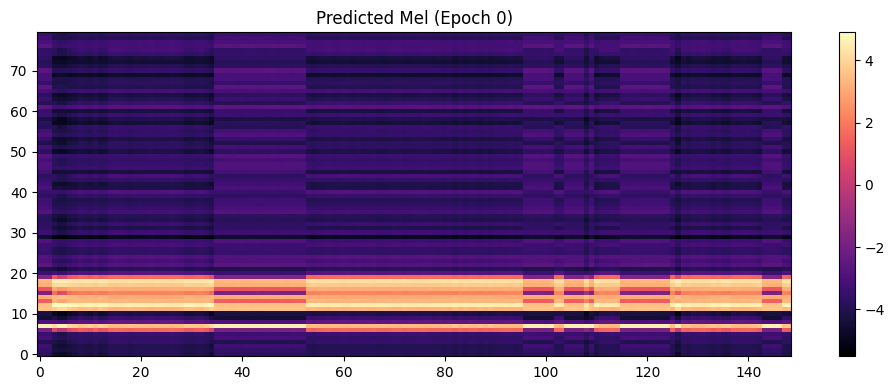

Epoch 0 | D Loss: 1.9325 | G Loss: 398.7978 | Duration Loss: 0.9407
Epoch 1 | D Loss: 1.9116 | G Loss: 399.1660 | Duration Loss: 0.9407
Epoch 2 | D Loss: 1.9175 | G Loss: 399.0986 | Duration Loss: 0.9407
Epoch 3 | D Loss: 1.9205 | G Loss: 399.2581 | Duration Loss: 0.9407
Epoch 4 | D Loss: 1.8798 | G Loss: 399.2063 | Duration Loss: 0.9407
Generated mel stats → min: -5.893691062927246 max: 5.187690734863281
Duration prediction → mean: 1.0


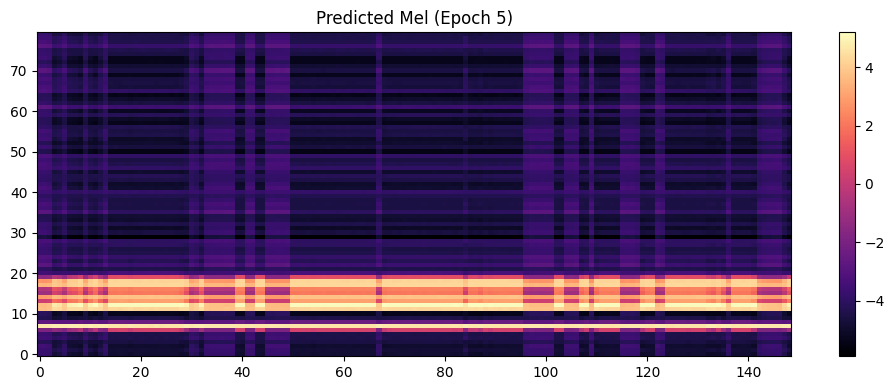

Epoch 5 | D Loss: 1.8353 | G Loss: 399.0025 | Duration Loss: 0.9407
Epoch 6 | D Loss: 1.7990 | G Loss: 398.9311 | Duration Loss: 0.9407
Epoch 7 | D Loss: 1.7636 | G Loss: 398.8313 | Duration Loss: 0.9407
Epoch 8 | D Loss: 1.7413 | G Loss: 398.8177 | Duration Loss: 0.9407
Epoch 9 | D Loss: 1.7120 | G Loss: 398.7847 | Duration Loss: 0.9407
Generated mel stats → min: -5.9596052169799805 max: 5.325090408325195
Duration prediction → mean: 1.0


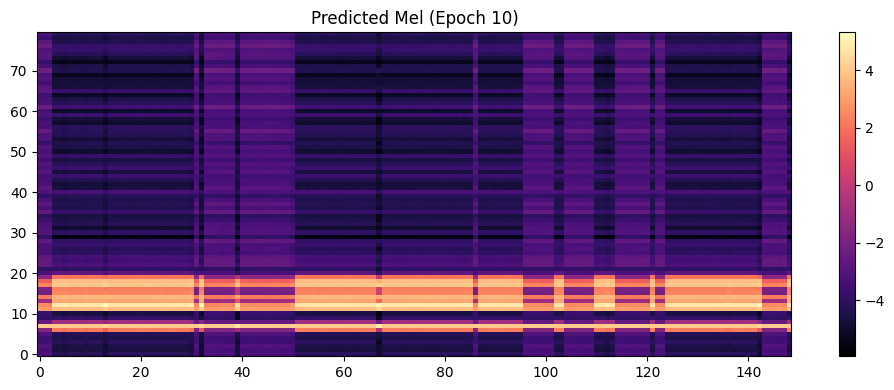

Epoch 10 | D Loss: 1.6775 | G Loss: 398.7051 | Duration Loss: 0.9407
Epoch 11 | D Loss: 1.6573 | G Loss: 398.6825 | Duration Loss: 0.9407
Epoch 12 | D Loss: 1.6430 | G Loss: 398.6677 | Duration Loss: 0.9407
Epoch 13 | D Loss: 1.6324 | G Loss: 398.6524 | Duration Loss: 0.9407
Epoch 14 | D Loss: 1.6252 | G Loss: 398.6679 | Duration Loss: 0.9407
Generated mel stats → min: -5.5385589599609375 max: 4.829489231109619
Duration prediction → mean: 1.0


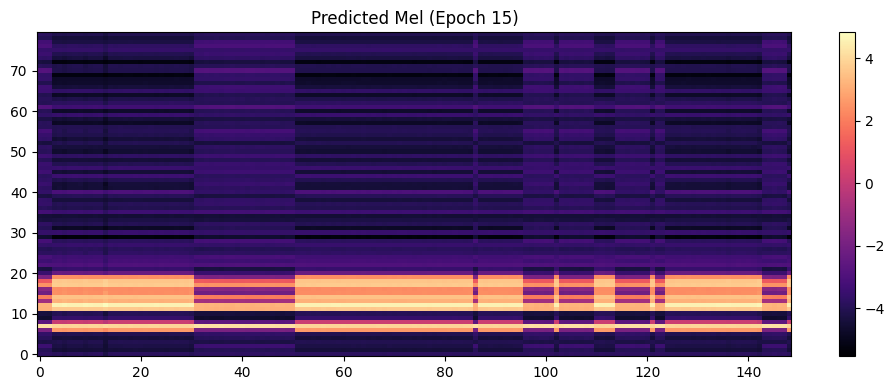

Epoch 15 | D Loss: 1.6213 | G Loss: 398.6490 | Duration Loss: 0.9407
Epoch 16 | D Loss: 1.6201 | G Loss: 398.6307 | Duration Loss: 0.9407
Epoch 17 | D Loss: 1.6229 | G Loss: 398.6272 | Duration Loss: 0.9407
Epoch 18 | D Loss: 1.6282 | G Loss: 398.6140 | Duration Loss: 0.9407
Epoch 19 | D Loss: 1.6361 | G Loss: 398.6000 | Duration Loss: 0.9407
Generated mel stats → min: -5.24661111831665 max: 4.476840019226074
Duration prediction → mean: 1.0


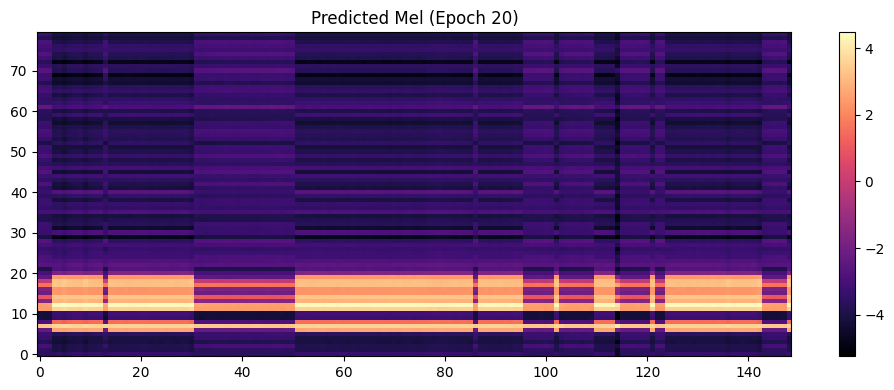

Epoch 20 | D Loss: 1.6358 | G Loss: 398.5790 | Duration Loss: 0.9407
Epoch 21 | D Loss: 1.6362 | G Loss: 398.5252 | Duration Loss: 0.9407
Epoch 22 | D Loss: 1.6369 | G Loss: 398.4997 | Duration Loss: 0.9407
Epoch 23 | D Loss: 1.6381 | G Loss: 398.4846 | Duration Loss: 0.9407
Epoch 24 | D Loss: 1.6383 | G Loss: 398.4475 | Duration Loss: 0.9407
Generated mel stats → min: -5.152691841125488 max: 4.540675163269043
Duration prediction → mean: 1.0


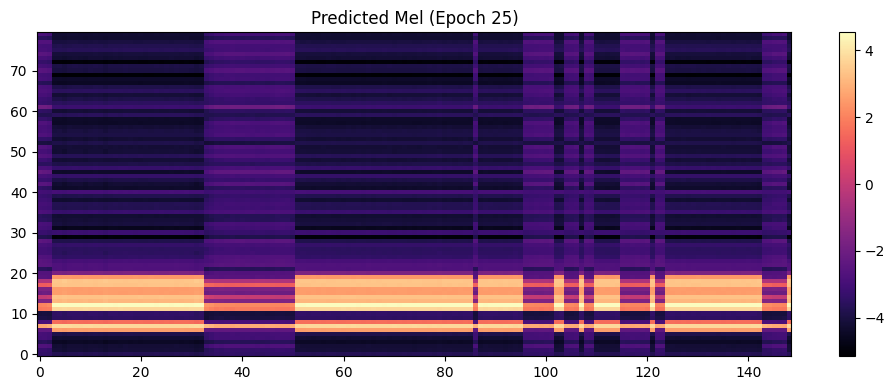

Epoch 25 | D Loss: 1.6351 | G Loss: 398.3861 | Duration Loss: 0.9407
Epoch 26 | D Loss: 1.6314 | G Loss: 398.3115 | Duration Loss: 0.9407
Epoch 27 | D Loss: 1.6285 | G Loss: 398.3070 | Duration Loss: 0.9407
Epoch 28 | D Loss: 1.6272 | G Loss: 398.2919 | Duration Loss: 0.9407
Epoch 29 | D Loss: 1.6265 | G Loss: 398.2707 | Duration Loss: 0.9407
Generated mel stats → min: -5.276087760925293 max: 4.603546619415283
Duration prediction → mean: 1.0


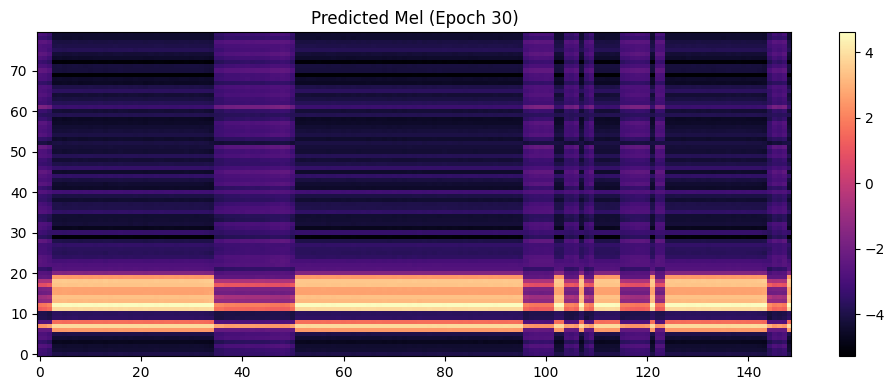

Epoch 30 | D Loss: 1.6273 | G Loss: 398.2562 | Duration Loss: 0.9407
Epoch 31 | D Loss: 1.6275 | G Loss: 398.2298 | Duration Loss: 0.9407
Epoch 32 | D Loss: 1.6283 | G Loss: 398.2222 | Duration Loss: 0.9407
Epoch 33 | D Loss: 1.6291 | G Loss: 398.2125 | Duration Loss: 0.9407
Epoch 34 | D Loss: 1.6300 | G Loss: 398.2027 | Duration Loss: 0.9407
Generated mel stats → min: -5.291966438293457 max: 4.621363639831543
Duration prediction → mean: 1.0


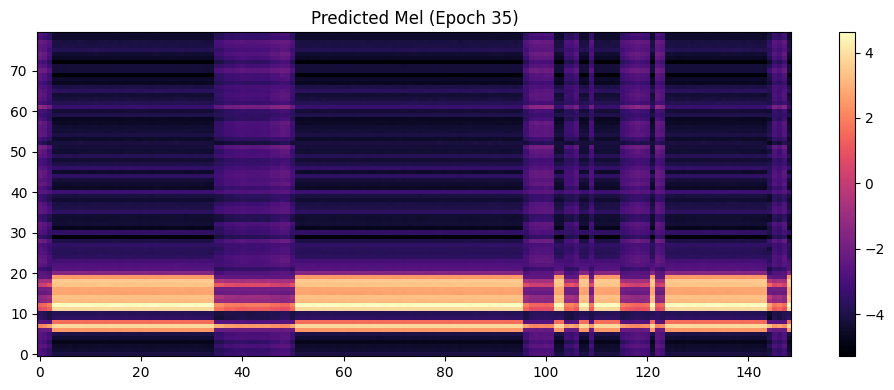

Epoch 35 | D Loss: 1.6310 | G Loss: 398.1914 | Duration Loss: 0.9407
Epoch 36 | D Loss: 1.6316 | G Loss: 398.1802 | Duration Loss: 0.9407
Epoch 37 | D Loss: 1.6325 | G Loss: 398.1694 | Duration Loss: 0.9407
Epoch 38 | D Loss: 1.6335 | G Loss: 398.1553 | Duration Loss: 0.9407
Epoch 39 | D Loss: 1.6338 | G Loss: 398.1377 | Duration Loss: 0.9407
Generated mel stats → min: -6.1053786277771 max: 5.3534393310546875
Duration prediction → mean: 1.0


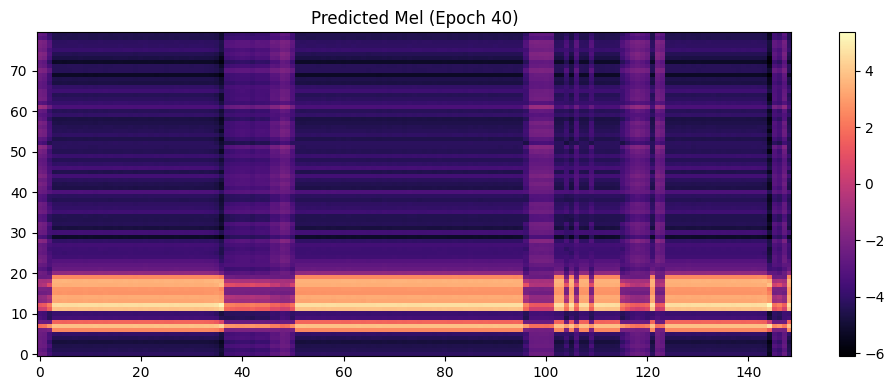

Epoch 40 | D Loss: 1.6318 | G Loss: 398.1063 | Duration Loss: 0.9407
Epoch 41 | D Loss: 1.6309 | G Loss: 398.1040 | Duration Loss: 0.9407
Epoch 42 | D Loss: 1.6298 | G Loss: 398.0974 | Duration Loss: 0.9407
Epoch 43 | D Loss: 1.6283 | G Loss: 398.0909 | Duration Loss: 0.9407
Epoch 44 | D Loss: 1.6259 | G Loss: 398.0327 | Duration Loss: 0.9407
Generated mel stats → min: -6.210452556610107 max: 4.666128158569336
Duration prediction → mean: 1.0


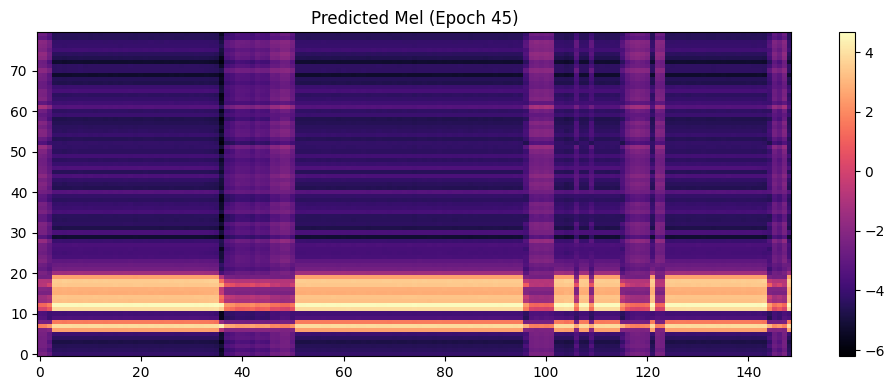

Epoch 45 | D Loss: 1.6244 | G Loss: 398.0198 | Duration Loss: 0.9407
Epoch 46 | D Loss: 1.6216 | G Loss: 398.0195 | Duration Loss: 0.9407
Epoch 47 | D Loss: 1.6202 | G Loss: 398.0065 | Duration Loss: 0.9407
Epoch 48 | D Loss: 1.6171 | G Loss: 398.0186 | Duration Loss: 0.9407
Epoch 49 | D Loss: 1.6153 | G Loss: 398.0017 | Duration Loss: 0.9407
Generated mel stats → min: -5.415602684020996 max: 4.682638168334961
Duration prediction → mean: 1.0


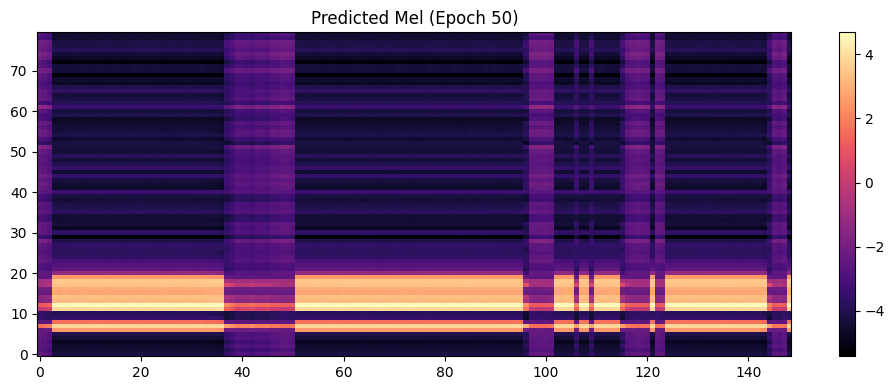

Epoch 50 | D Loss: 1.6130 | G Loss: 397.9966 | Duration Loss: 0.9407
Epoch 51 | D Loss: 1.6116 | G Loss: 397.9932 | Duration Loss: 0.9407
Epoch 52 | D Loss: 1.6107 | G Loss: 397.9914 | Duration Loss: 0.9407
Epoch 53 | D Loss: 1.6098 | G Loss: 397.9865 | Duration Loss: 0.9407
Epoch 54 | D Loss: 1.6091 | G Loss: 397.9827 | Duration Loss: 0.9407
Generated mel stats → min: -5.366872310638428 max: 4.673406600952148
Duration prediction → mean: 1.0


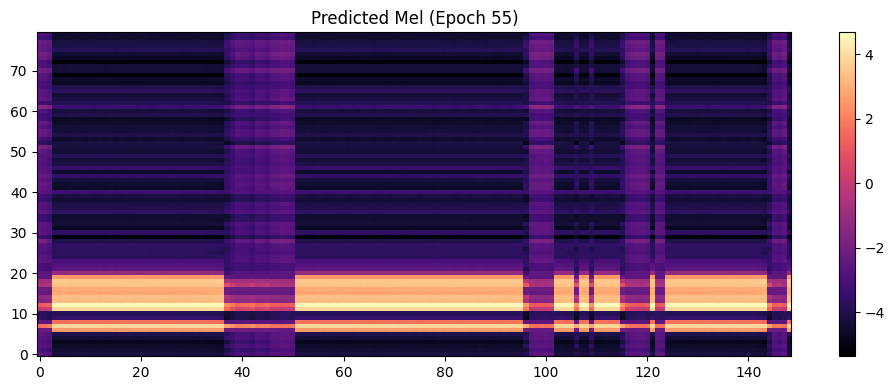

Epoch 55 | D Loss: 1.6086 | G Loss: 397.9812 | Duration Loss: 0.9407
Epoch 56 | D Loss: 1.6079 | G Loss: 397.9787 | Duration Loss: 0.9407
Epoch 57 | D Loss: 1.6073 | G Loss: 397.9752 | Duration Loss: 0.9407
Epoch 58 | D Loss: 1.6064 | G Loss: 397.9702 | Duration Loss: 0.9407
Epoch 59 | D Loss: 1.6056 | G Loss: 397.9686 | Duration Loss: 0.9407
Generated mel stats → min: -5.353090763092041 max: 4.613393783569336
Duration prediction → mean: 1.0


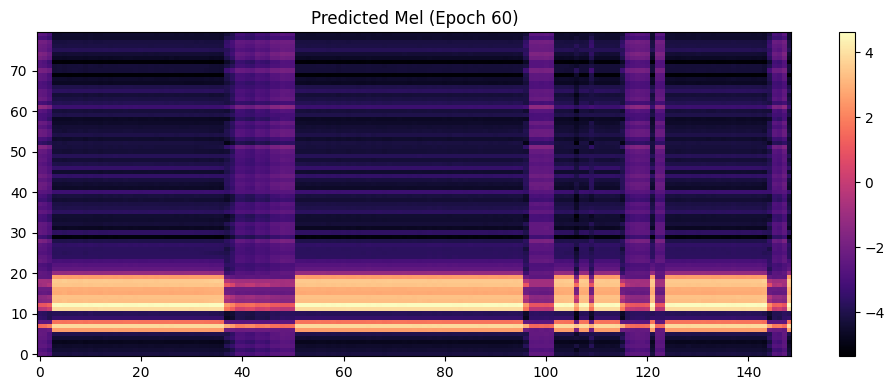

Epoch 60 | D Loss: 1.6048 | G Loss: 397.9604 | Duration Loss: 0.9407
Epoch 61 | D Loss: 1.6043 | G Loss: 397.9608 | Duration Loss: 0.9407
Epoch 62 | D Loss: 1.6030 | G Loss: 397.9441 | Duration Loss: 0.9407
Epoch 63 | D Loss: 1.6030 | G Loss: 397.9473 | Duration Loss: 0.9407
Epoch 64 | D Loss: 1.6019 | G Loss: 397.9424 | Duration Loss: 0.9407
Generated mel stats → min: -5.309758186340332 max: 4.606482028961182
Duration prediction → mean: 1.0


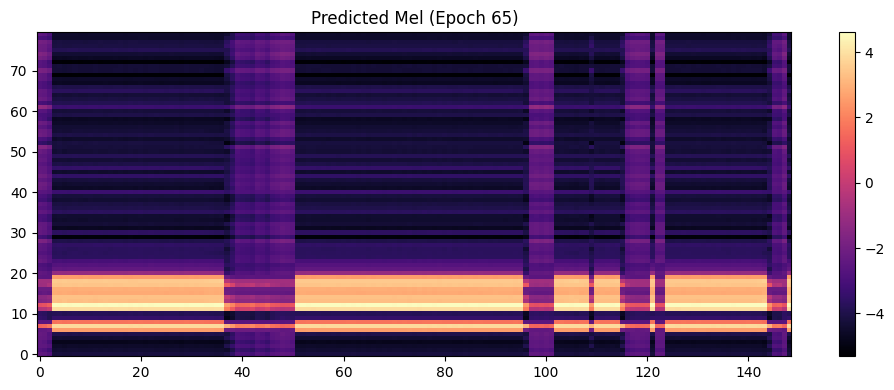

Epoch 65 | D Loss: 1.6012 | G Loss: 397.9401 | Duration Loss: 0.9407
Epoch 66 | D Loss: 1.6007 | G Loss: 397.9390 | Duration Loss: 0.9407
Epoch 67 | D Loss: 1.6005 | G Loss: 397.9373 | Duration Loss: 0.9407
Epoch 68 | D Loss: 1.5999 | G Loss: 397.9365 | Duration Loss: 0.9407
Epoch 69 | D Loss: 1.5998 | G Loss: 397.9341 | Duration Loss: 0.9407
Generated mel stats → min: -5.297692775726318 max: 4.602640628814697
Duration prediction → mean: 1.0


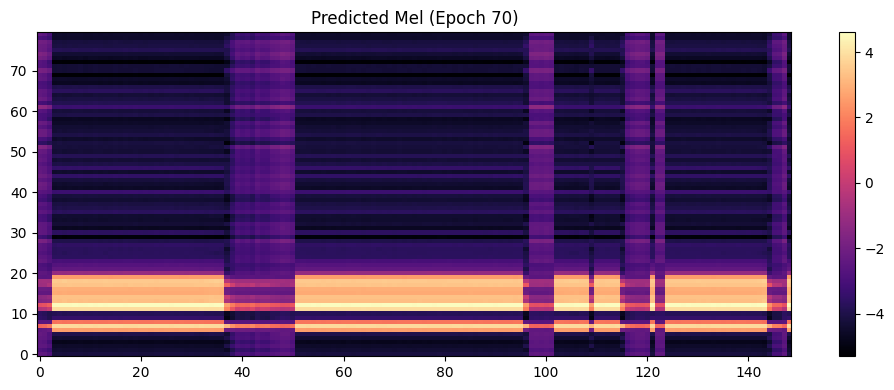

Epoch 70 | D Loss: 1.5997 | G Loss: 397.9329 | Duration Loss: 0.9407
Epoch 71 | D Loss: 1.5995 | G Loss: 397.9309 | Duration Loss: 0.9407
Epoch 72 | D Loss: 1.5993 | G Loss: 397.9328 | Duration Loss: 0.9407
Epoch 73 | D Loss: 1.5992 | G Loss: 397.9288 | Duration Loss: 0.9407
Epoch 74 | D Loss: 1.5992 | G Loss: 397.9295 | Duration Loss: 0.9407
Generated mel stats → min: -5.301098346710205 max: 4.603607654571533
Duration prediction → mean: 1.0


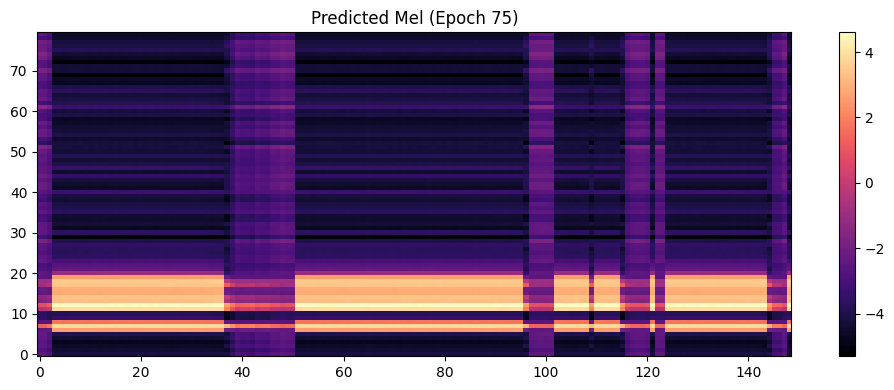

Epoch 75 | D Loss: 1.5991 | G Loss: 397.9283 | Duration Loss: 0.9407
Epoch 76 | D Loss: 1.5989 | G Loss: 397.9277 | Duration Loss: 0.9407
Epoch 77 | D Loss: 1.5988 | G Loss: 397.9268 | Duration Loss: 0.9407
Epoch 78 | D Loss: 1.5987 | G Loss: 397.9254 | Duration Loss: 0.9407
Epoch 79 | D Loss: 1.5988 | G Loss: 397.9258 | Duration Loss: 0.9407
Generated mel stats → min: -5.295304775238037 max: 4.615265369415283
Duration prediction → mean: 1.0


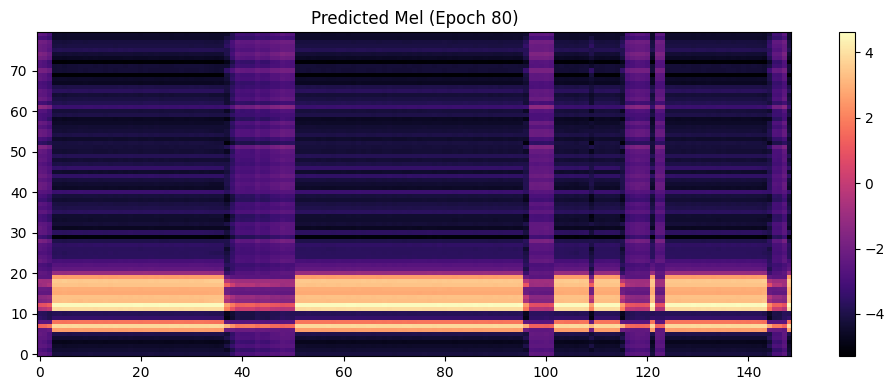

Epoch 80 | D Loss: 1.5986 | G Loss: 397.9240 | Duration Loss: 0.9407
Epoch 81 | D Loss: 1.5986 | G Loss: 397.9233 | Duration Loss: 0.9407
Epoch 82 | D Loss: 1.5987 | G Loss: 397.9242 | Duration Loss: 0.9407
Epoch 83 | D Loss: 1.5986 | G Loss: 397.9222 | Duration Loss: 0.9407
Epoch 84 | D Loss: 1.5987 | G Loss: 397.9236 | Duration Loss: 0.9407
Generated mel stats → min: -5.285046100616455 max: 4.589103698730469
Duration prediction → mean: 1.0


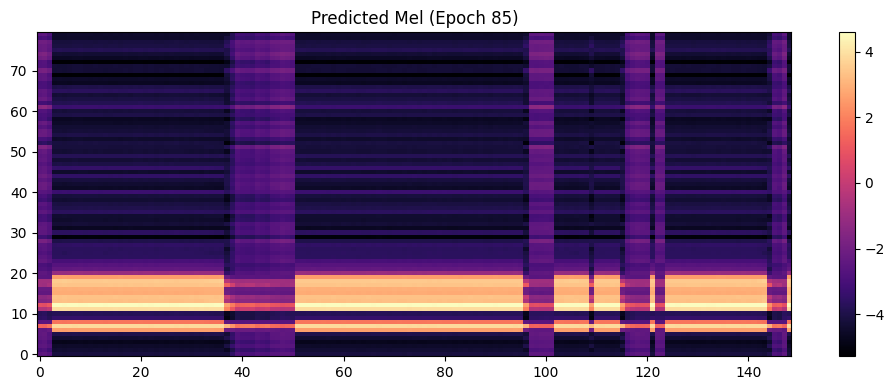

Epoch 85 | D Loss: 1.5986 | G Loss: 397.9220 | Duration Loss: 0.9407
Epoch 86 | D Loss: 1.5987 | G Loss: 397.9218 | Duration Loss: 0.9407
Epoch 87 | D Loss: 1.5988 | G Loss: 397.9216 | Duration Loss: 0.9407
Epoch 88 | D Loss: 1.5987 | G Loss: 397.9202 | Duration Loss: 0.9407
Epoch 89 | D Loss: 1.5988 | G Loss: 397.9207 | Duration Loss: 0.9407
Generated mel stats → min: -5.29188871383667 max: 4.59960412979126
Duration prediction → mean: 1.0


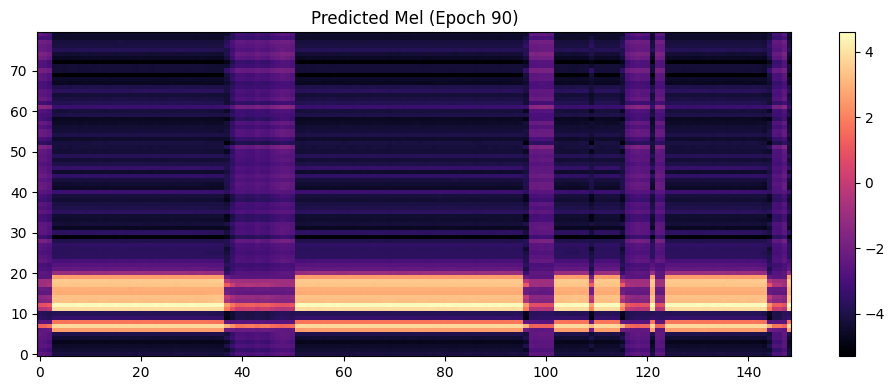

Epoch 90 | D Loss: 1.5989 | G Loss: 397.9200 | Duration Loss: 0.9407
Epoch 91 | D Loss: 1.5989 | G Loss: 397.9198 | Duration Loss: 0.9407
Epoch 92 | D Loss: 1.5988 | G Loss: 397.9208 | Duration Loss: 0.9407
Epoch 93 | D Loss: 1.5989 | G Loss: 397.9197 | Duration Loss: 0.9407
Epoch 94 | D Loss: 1.5988 | G Loss: 397.9194 | Duration Loss: 0.9407
Generated mel stats → min: -5.277768611907959 max: 4.591425895690918
Duration prediction → mean: 1.0


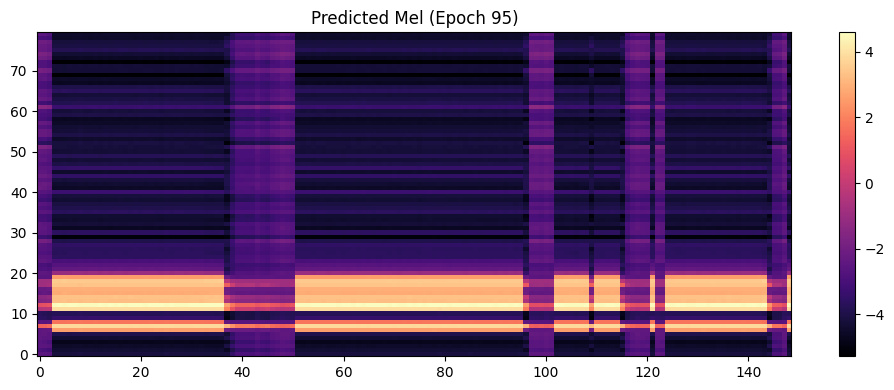

Epoch 95 | D Loss: 1.5989 | G Loss: 397.9189 | Duration Loss: 0.9407
Epoch 96 | D Loss: 1.5989 | G Loss: 397.9196 | Duration Loss: 0.9407
Epoch 97 | D Loss: 1.5989 | G Loss: 397.9171 | Duration Loss: 0.9407
Epoch 98 | D Loss: 1.5989 | G Loss: 397.9190 | Duration Loss: 0.9407
Epoch 99 | D Loss: 1.5989 | G Loss: 397.9174 | Duration Loss: 0.9407


In [121]:
# === Training Loop ===
# dataset = SimpleLJSDataset("LJSpeech-1.1/LJSpeech-1.1/metadata.csv", "LJSpeech-1.1/LJSpeech-1.1/wavs", duration_dir="durations")
dataset = SimpleLJSDataset(
    metadata_path="LJSpeech-1.1/LJSpeech-1.1/metadata.csv",
    wav_dir="LJSpeech-1.1/LJSpeech-1.1/wavs_16k",
    duration_dir="LJSpeech-1.1/LJSpeech-1.1/durations_npy"
)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True, collate_fn=collate_fn)

criterion = torch.nn.MSELoss()
duration_criterion = torch.nn.L1Loss()  # ✅ Add L1 loss for durations

optimizer_g = torch.optim.Adam(model.parameters(), lr=0.001)
optimizer_d = torch.optim.Adam(model.discriminator.parameters(), lr=0.001)

scheduler_g = torch.optim.lr_scheduler.StepLR(optimizer_g, step_size=10, gamma=0.5)
scheduler_d = torch.optim.lr_scheduler.StepLR(optimizer_d, step_size=10, gamma=0.5)


model.train()
for epoch in range(100):
    for text_seq, mel_target, true_durations, text_lens in dataloader:
        # === Text encoding ===
        text_features = model.text_encoder(text_seq)  # (B, T_text, hidden_dim)

        # === Predict durations with the model ===
        predicted_durations = model.duration_predictor(text_features)  # (B, T_text)
        
        # Instead of masking with index tensors...
        # Assume both are shape (B, T), where T may differ due to padding
        B, T = predicted_durations.shape
        # true_durations = true_durations[:, :T]  # Truncate to match pred shape if necessary
        
        # Pad true_durations to match predicted_durations shape
        if true_durations.shape[1] < T:
            pad_size = T - true_durations.shape[1]
            true_durations = F.pad(true_durations, (0, pad_size), value=0.0)
        else:
            true_durations = true_durations[:, :T]


        mask = torch.arange(T, device=predicted_durations.device).expand(B, T) < text_lens.unsqueeze(1)

        # Now apply the mask
        masked_pred = predicted_durations[mask]
        masked_true = true_durations[mask]

        duration_loss = duration_criterion(masked_pred, masked_true)

        # === Apply length regulator ===
        regulated = model.length_regulator(text_features, predicted_durations)  # (B, T_mel, hidden_dim)

        # === Project to mel space ===
        predicted_mel = model.text_to_mel_proj(regulated)  # (B, T_mel, mel_dim)

        # === Apply diffusion blocks with noise (training=True) ===
        for step, block in enumerate(model.mel_generator.diffusion_blocks):
            predicted_mel = block(predicted_mel, step, add_noise=True)

        # === Train GAN ===
        d_loss, g_loss, duration_loss = train_step(
            generator=model,
            discriminator=model.discriminator,
            optimizer_g=optimizer_g,
            optimizer_d=optimizer_d,
            real_mels=mel_target,
            text_input=text_seq,
            true_durations=true_durations,
            text_lens=text_lens,
            criterion=criterion,
            duration_criterion=duration_criterion,
            duration_loss_weight=1.0, 
            scheduler_g=scheduler_g,
            scheduler_d=scheduler_d,
            gan_weight=0.01
        )
        
        if epoch % 5 == 0:  # Every 5 epochs
            with torch.no_grad():
                print("Generated mel stats → min:", predicted_mel.min().item(), "max:", predicted_mel.max().item())
                print("Duration prediction → mean:", predicted_durations.float().mean().item())

                # Optional: visualize first sample's mel
                import matplotlib.pyplot as plt
                plt.figure(figsize=(10, 4))
                plt.imshow(predicted_mel[0].cpu().detach().T, origin='lower', aspect='auto', cmap='magma')
                plt.title(f"Predicted Mel (Epoch {epoch})")
                plt.colorbar()
                plt.tight_layout()
                plt.show()


        print(f"Epoch {epoch} | D Loss: {d_loss:.4f} | G Loss: {g_loss:.4f} | Duration Loss: {duration_loss:.4f}")



Griffin Lim - Mel Spec to Audio 

In [122]:
def mel_to_waveform(mel_spec, sample_rate=16000, n_fft=1024, hop_length=256):
    """
    Convert a predicted mel spectrogram (1, T, mel_dim) to waveform.
    """
    # Convert shape to (mel_dim, T)
    if mel_spec.shape[1] == 80:  # (1, 80, T)
        mel_spec = mel_spec.squeeze(0)
    else:  # (1, T, 80)
        mel_spec = mel_spec.squeeze(0).transpose(0, 1)

    # Undo AmplitudeToDB if needed — skip if already linear
    mel_spec = 10 ** (mel_spec / 20)

    n_mels, T = mel_spec.shape

    # Create mel basis and invert to linear spectrogram
    mel_basis = torchaudio.functional.melscale_fbanks(
        n_freqs=n_fft // 2 + 1,
        f_min=0.0,
        f_max=sample_rate / 2.0,
        n_mels=n_mels,
        sample_rate=sample_rate,
        norm='slaney',
        mel_scale='htk'
    )

    mel_basis = mel_basis.T  # (n_mels, n_freqs)
    mel_inv = torch.pinverse(mel_basis)  # (n_freqs, n_mels)
    linear_spec = torch.matmul(mel_inv, mel_spec)  # (n_freqs, T)

    # Run Griffin-Lim with known T
    griffin_lim = torchaudio.transforms.GriffinLim(
        n_fft=n_fft,
        hop_length=hop_length,
        n_iter=32
    )

    waveform = griffin_lim(linear_spec)  # should have T * hop_length samples
    return waveform.unsqueeze(0)  # (1, num_samples)


Inference Stage

torch.Size([1, 15])
torch.Size([1, 3584])
Waveform length: 3584 samples
Duration: 0.22 seconds
Generated mel shape: torch.Size([1, 80, 15])


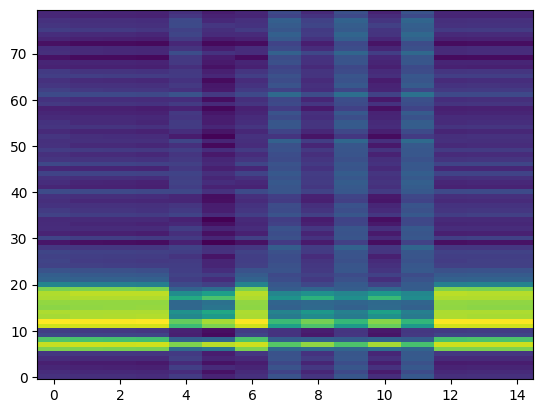

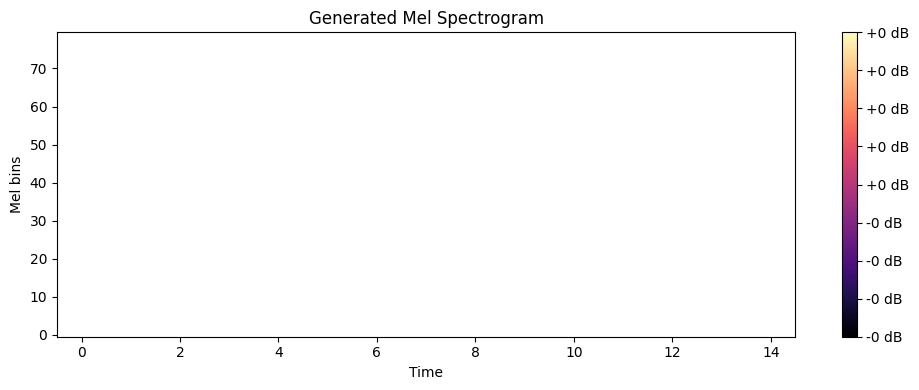

In [127]:
# Inference: Use the full model forward pass
text = "this is a house"
text_seq = torch.tensor([text_to_sequence(text)])  # (1, T_text)
print(text_seq.shape)

model.eval()
with torch.no_grad():
    # Use the full forward pass which includes the duration predictor and length regulator.
    predicted_mel = model(text_seq)  # (1, T_mel, mel_dim)
    

    # print("Generated waveform shape:", waveform.shape)
    plt.imshow(predicted_mel[0].cpu().detach().numpy().T, aspect='auto', origin='lower')
    
    # Generate waveform from the mel spectrogram
    waveform = mel_to_waveform(predicted_mel)
    print(waveform.shape)  # (1, T)
    # Optionally, save the generated audio
    # torchaudio.save("generated.wav", waveform, sample_rate=16000)
    
    # Print waveform info
    num_samples = waveform.shape[1]
    duration_sec = num_samples / 16000
    print(f"Waveform length: {num_samples} samples")
    print(f"Duration: {duration_sec:.2f} seconds")
  
    
    generated_mel = mel_transform(waveform)  # (1, mel_dim, T)
    print("Generated mel shape:", generated_mel.shape)
    mel_db = torchaudio.transforms.AmplitudeToDB()(generated_mel)
    
    # Plot the generated mel spectrogram
    plt.figure(figsize=(10, 4))
    plt.imshow(mel_db[0].numpy()[::-1], origin="lower", aspect="auto", cmap="magma")
    # plt.imshow(mel_db[0].cpu().detach().numpy().T, origin='lower', aspect='auto')
    plt.title("Generated Mel Spectrogram")
    plt.xlabel("Time")
    plt.ylabel("Mel bins")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout()
    plt.show()
